# NLP Sarcasm Detection using Multi-Task RoBERTa with Sentiment-Incongruence Analysis

**MCA AI/ML — Continuous Assessment (CA) Project**

**CA brief:** *Select a pre-trained deep learning model and study its architecture, working
process, performance, strengths, and limitations. Prepare a short report and present your findings.*

**Model studied:** RoBERTa (`roberta-base`), fine-tuned in two configurations —
a standard single-task sarcasm classifier and a multi-task classifier that shares its encoder
with an auxiliary sentiment-classification head.

**Central research question**

> Can contextual representations from RoBERTa improve sarcasm detection compared with
> traditional TF-IDF-based classification, and does auxiliary sentiment learning provide
> additional benefit for identifying sarcastic language?

---

### ⚠️ Notebook status — read this first

This is a **corrected rebuild** of an earlier version of this notebook. The earlier version had
five methodological problems (data leakage in the test split, a sentiment head trained on fake
labels derived from the sarcasm label itself, sarcasm ground-truth invented from ordinary
sentiment polarity, an invalid "Twitter" label for what is actually a news-headlines dataset,
and cross-domain "sarcasm" scores computed from heuristics). Each is fixed here — see the
**Summary of Changes** at the end of the notebook for the full list.

All custom logic in this notebook (the leakage-free splitter, the ABSA label handling, the
multi-task training loop, the evaluation code, the LIME wrapper, and the error-analysis code)
was unit-tested offline against synthetic data and a randomly-initialised tiny transformer
before being wired up to the real `roberta-base` weights, so the code paths below are known to
run without shape or logic errors. **You still need to run this notebook yourself** — on Kaggle
or Colab, with a GPU and the datasets attached — to get real accuracy numbers; no numbers in
this notebook are fabricated in advance.

**Datasets required (attach these on Kaggle, or place the files in a `./data` folder):**
- News Headlines Sarcasm Dataset (`Sarcasm_Headlines_Dataset_v2.json`)
- SemEval-2014 ABSA Laptop + Restaurant CSVs (Train, Trial, Test PhaseA, Test PhaseB, for both domains)
- Amazon Unlocked Mobile Reviews (`Amazon_Unlocked_Mobile.csv`) — used only for qualitative analysis


## 1. Problem Statement

Sarcasm is a form of language in which the literal (surface) meaning of a sentence is opposite
to, or inconsistent with, the meaning the speaker intends. It is a well-known failure mode for
ordinary sentiment analysis systems: a sentence like *"I just love waiting three hours for my
food"* has positive surface wording but a clearly negative intended meaning. A system that only
looks at word-level sentiment will misclassify it.

**Task:** given a piece of text, predict whether it is sarcastic or not — a binary
classification problem.

## 2. Objective

1. Fine-tune RoBERTa, a pre-trained transformer language model, for supervised sarcasm
   detection, and study its architecture in enough depth to explain it in a viva.
2. Add an auxiliary sentiment-classification head trained on **real** sentiment-labelled data,
   sharing the same encoder, and test whether this auxiliary task helps the primary sarcasm task.
3. Use the **mismatch between surface sentiment and other signals** (sentiment incongruence) as
   an interpretability/analysis tool that helps explain *why* the model may have flagged
   something as sarcastic — without treating that mismatch as ground truth.
4. Compare against a traditional TF-IDF + Logistic Regression baseline, using identical,
   leakage-free train/validation/test splits, and report honest metrics — not just accuracy.


## 3. Why Sarcasm Detection?

- It is a genuinely hard NLP problem: it requires modelling context, not just word polarity.
- It has direct applications in social-media monitoring, customer-feedback analysis, and
  sentiment-analysis pipelines, where sarcastic text is a major source of misclassification.
- It is a good vehicle for demonstrating **contextual** representations (RoBERTa) versus
  **bag-of-words** representations (TF-IDF), because sarcasm detection is one of the tasks where
  the difference between the two is most visible.

**Important scoping note, stated up front and honoured throughout this notebook:**
Sentiment incongruence (positive wording + negative underlying signal) is a *useful correlate*
of sarcasm, not a definition of it. Negative sentiment is not sarcasm, and positive sentiment is
not "safely non-sarcastic" either. Sarcasm detection here is therefore treated strictly as a
**supervised classification task trained on real, human-annotated sarcasm labels**; sentiment
incongruence is only ever used as a downstream *analysis/interpretability* signal, never as a
source of training or evaluation labels.


## 4. Why RoBERTa?

RoBERTa ("Robustly Optimized BERT Pretraining Approach") is a transformer encoder pre-trained
with masked-language-modelling on a very large text corpus, using the same architecture as BERT
but with training-procedure changes (no next-sentence-prediction task, larger batches, more
data, dynamic masking) that make it a stronger starting point for fine-tuning.

Why it fits this task better than TF-IDF or a plain RNN/LSTM:

| Property | TF-IDF + LogReg | LSTM (from scratch) | RoBERTa (pre-trained) |
|---|---|---|---|
| Uses word order / context | ✗ (bag of words) | ✓ (sequential) | ✓ (full self-attention) |
| Pre-trained language knowledge | ✗ | ✗ | ✓ (large corpus) |
| Handles long-range dependencies | ✗ | partially (vanishing gradient) | ✓ |
| Needs large labelled data to work well | mostly, still limited ceiling | yes, a lot | less — fine-tuning transfers prior knowledge |
| Captures subword / rare-word info | partial (n-grams) | limited | ✓ (byte-level BPE) |

Sarcasm detection depends on **how words relate to each other in context**
(e.g. "great" next to "waiting three hours" is what signals sarcasm — neither word alone does),
which is exactly what self-attention is designed to model.


## 5. Architecture Overview

```
                         DATASETS
           (News Headlines Sarcasm | SemEval ABSA | Amazon*)
                             |
                             v
                    Text Preprocessing
                    (conservative cleaning)
                             |
                             v
                  RoBERTa Tokenizer (BPE)
                             |
                             v
                    RoBERTa-base Encoder
                     (shared, 12 layers)
                             |
                   Contextual [CLS] representation
                     +-----------+-----------+
                     |                       |
                     v                       v
              Sarcasm Head              Sentiment Head
           (Sarcastic / Not)      (Positive / Negative / Neutral)
                     |                       |
                     +-----------+-----------+
                                 |
                                 v
                  Sentiment-Incongruence Analysis
                    (post-hoc, qualitative signal)
                                 |
                                 v
                        Final Prediction
                                 |
                                 v
                         LIME Explanation
                                 |
                                 v
                          Prototype Demo
```
*Amazon data is used only for qualitative / domain-transfer analysis — see Section 18.

**Three models are trained and compared** on the same leakage-free sarcasm test set:

| # | Model | Encoder | Heads | Loss |
|---|---|---|---|---|
| 1 | TF-IDF + Logistic Regression | — (bag of words) | 1 (sarcasm) | log-loss |
| 2 | Standard RoBERTa | `roberta-base` | 1 (sarcasm) | Cross-Entropy |
| 3 | **Multi-Task RoBERTa** | `roberta-base` (shared) | 2 (sarcasm + sentiment) | 0.7·L_sarcasm + 0.3·L_sentiment |
| 4 (ablation) | RoBERTa + Focal Loss | `roberta-base` | 1 (sarcasm) | Focal Loss (γ=2) |


## 6. Dataset Description

**A note on naming, corrected in this version:** an earlier version of this notebook referred to
the main sarcasm dataset as "Twitter" data. That was wrong — the file is
`Sarcasm_Headlines_Dataset_v2.json`, a collection of **news headlines** (from The Onion for
sarcastic headlines and HuffPost for non-sarcastic ones), not tweets. It is referred to as the
**News Headlines Sarcasm Dataset** (or "main sarcasm dataset") everywhere in this notebook.

| Dataset | Rows (approx.) | Labels | Ground truth for | Role in this notebook |
|---|---|---|---|---|
| News Headlines Sarcasm Dataset | ~28,619 | `is_sarcastic` (0/1), ~47.5% sarcastic | **Sarcasm** | Primary — train/val/test for all sarcasm models |
| SemEval-2014 ABSA — Laptop | Train 2,358 / Trial 49 / PhaseA 800 / PhaseB 800 | `polarity` ∈ {positive, negative, neutral, conflict} | **Sentiment (aspect-level)** | Train/val/test for the auxiliary sentiment head |
| SemEval-2014 ABSA — Restaurant | Train 3,693 / Trial 96 / PhaseA 800 / PhaseB 800 | `polarity` ∈ {positive, negative, neutral, conflict} | **Sentiment (aspect-level)** | Train/val/test for the auxiliary sentiment head |
| Amazon Unlocked Mobile Reviews | 413,840 raw (≈3,000 sampled) | star rating (1–5) | Sentiment (rating), **not sarcasm** | Qualitative domain-transfer / incongruence analysis only |

**Important distinction that earlier versions of this project blurred:** the ABSA datasets carry
real **sentiment** polarity labels, not sarcasm labels. They are the correct source of ground
truth for the auxiliary sentiment task, but they must never be relabelled into sarcasm ground
truth (e.g. "negative polarity → sarcastic"). That relationship does not hold — *"the battery
life is terrible"* is negative and completely sincere, not sarcastic.


## 7. Install Dependencies

Run this once. Versions are loosely pinned to known-compatible ranges rather than exact
versions, since exact old pins tend to break as Kaggle/Colab base images update.


                         PROBLEM
                            │
                            ▼
                  Sarcasm Detection
                            │
                            ▼
               Traditional Baseline
              TF-IDF + Logistic Regression
                            │
                            ▼
                    Pre-trained Model
                       RoBERTa-base
                            │
                            ▼
                Standard RoBERTa Model
                            │
                            ▼
                  Proposed Improvement
                Multi-Task RoBERTa
                    /           \
                   /             \
          Sarcasm Task       Sentiment Task
               │                   │
               └────────┬──────────┘
                        ▼
                 Shared Encoder
                        │
                        ▼
                 Model Comparison
                        │
                        ▼
              Performance Evaluation
                        │
          ┌─────────────┼─────────────┐
          ▼             ▼             ▼
      F1/AUC       Confusion       ROC Curve
                    Matrix
                        │
                        ▼
              Error Analysis
                        │
                        ▼
          Sentiment-Incongruence
                 Analysis
                        │
                        ▼
                   LIME
               Explainability
                        │
                        ▼
                 Prototype Demo
                        │
                        ▼
             Strengths / Limitations
                        │
                        ▼
               Future Improvements

In [1]:
import subprocess, sys

pkgs = [
    "transformers>=4.41.0,<5.0.0",
    "torch",
    "scikit-learn",
    "lime",
    "matplotlib",
    "seaborn",
    "pandas",
    "numpy",
    "tqdm",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + pkgs)
print("Packages installed.")


Packages installed.


## 8. Imports

In [2]:
import os, re, glob, json, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import RobertaTokenizerFast, RobertaModel, get_linear_schedule_with_warmup

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
)
from lime.lime_text import LimeTextExplainer

sns.set_theme(style="whitegrid", palette="muted")
print("Imports OK.")


Imports OK.


## 9. Configuration

In [3]:
def find_dataset_dir(filename_hint="Sarcasm_Headlines_Dataset_v2.json"):
    '''Search common Kaggle/Colab/local locations for the dataset files.
    Returns a dict {filename: full_path} built lazily by locate_file() below instead of
    assuming one shared folder, because on Kaggle each attached dataset gets its own directory.
    '''
    search_roots = ["/kaggle/input", "./data", "../data", "./nlp_dataset", "../nlp_dataset", "."]
    existing_roots = [r for r in search_roots if os.path.exists(r)]
    return existing_roots

SEARCH_ROOTS = find_dataset_dir()
print("Search roots found:", SEARCH_ROOTS)

_FILE_CACHE = {}
def locate_file(filename):
    '''Recursively search all known roots for `filename`. Cached after first lookup.'''
    if filename in _FILE_CACHE:
        return _FILE_CACHE[filename]
    for root in SEARCH_ROOTS:
        matches = glob.glob(os.path.join(root, "**", filename), recursive=True)
        if matches:
            _FILE_CACHE[filename] = matches[0]
            return matches[0]
    _FILE_CACHE[filename] = None
    return None


class Config:
    MODEL_NAME    = "roberta-base"
    MAX_LEN       = 128

    SEED          = 42
    BATCH_SIZE    = 16
    EPOCHS        = 4
    LR            = 2e-5
    WEIGHT_DECAY  = 0.01
    WARMUP_RATIO  = 0.10
    DROPOUT       = 0.15
    MAX_GRAD_NORM = 1.0

    # Multi-task loss weights (primary task weighted higher)
    ALPHA_SARCASM  = 0.70
    BETA_SENTIMENT = 0.30

    # Ablation switch — trains an extra RoBERTa+FocalLoss model for comparison.
    # The main sarcasm dataset is close to balanced (~47.5%/52.5%), so Focal Loss
    # is NOT expected to be necessary; this flag lets the notebook prove that empirically
    # instead of assuming it.
    RUN_FOCAL_LOSS_ABLATION = True
    FOCAL_GAMMA = 2.0

    SARCASM_ID2LABEL   = {0: "not_sarcastic", 1: "sarcastic"}
    SENTIMENT_ID2LABEL = {0: "negative", 1: "neutral", 2: "positive"}

    OUTPUT_DIR = "./sarcasm_outputs"
    DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CFG = Config()
os.makedirs(CFG.OUTPUT_DIR, exist_ok=True)

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(CFG.SEED)

print(f"Device : {CFG.DEVICE}")
print(f"Model  : {CFG.MODEL_NAME}")
if CFG.DEVICE.type == "cpu":
    print("WARNING: no GPU detected. Fine-tuning RoBERTa on CPU will be very slow — "
          "on Kaggle/Colab, enable a GPU accelerator (Settings > Accelerator > GPU) before running.")


Search roots found: ['.']
Device : cpu
Model  : roberta-base


## 10. Load Datasets

In [13]:
import os
from pathlib import Path
import pandas as pd


# ============================================================
# Helper 1: Find a column safely
# ============================================================

def find_col(df, candidates):
    """
    Find a dataframe column using case-insensitive matching.
    Example:
        find_col(df, ["headline", "text"])
    """
    lower = {str(c).lower().strip(): c for c in df.columns}

    for candidate in candidates:
        candidate = candidate.lower().strip()

        if candidate in lower:
            return lower[candidate]

    return None


# ============================================================
# Helper 2: Read CSV safely with different encodings
# ============================================================

def safe_read_csv(path):
    """
    Try multiple encodings so that CSV files with different
    character encodings can be loaded safely.
    """

    encodings = [
        "utf-8",
        "utf-8-sig",
        "latin-1",
        "cp1252"
    ]

    for encoding in encodings:
        try:
            return pd.read_csv(
                path,
                encoding=encoding,
                on_bad_lines="skip"
            )

        except Exception:
            continue

    raise ValueError(
        f"Could not read CSV file: {path}"
    )


# ============================================================
# Helper 3: Locate a file anywhere inside the project folder
# ============================================================

def locate_file(filename):
    """
    Search for a file starting from the current notebook
    working directory.

    This works for:
        - Windows
        - Jupyter Notebook
        - VS Code
        - Local project folders
        - Kaggle (if /kaggle/input is available)
        - Google Colab (if /content is available)
    """

    search_roots = [
        Path.cwd(),
        Path("./data"),
        Path("../data"),
        Path("/kaggle/input"),
        Path("/content")
    ]

    for root in search_roots:

        if not root.exists():
            continue

        try:
            matches = list(root.rglob(filename))

            if matches:
                return str(matches[0])

        except Exception:
            continue

    return None


# ============================================================
# 1. MAIN SARCASM DATASET
#    News Headlines Dataset for Sarcasm Detection
# ============================================================

print("=" * 70)
print("1. Loading Main Sarcasm Dataset")
print("=" * 70)

# Your project contains the v2 filename
_headlines_path = locate_file(
    "Sarcasm_Headlines_Dataset_v2.json"
)

# Also support the original filename as a fallback
if _headlines_path is None:

    _headlines_path = locate_file(
        "Sarcasm_Headlines_Dataset.json"
    )


# Stop if neither file exists
if _headlines_path is None:

    raise FileNotFoundError(
        "\nSarcasm dataset not found.\n\n"
        "Expected one of:\n"
        "  - Sarcasm_Headlines_Dataset_v2.json\n"
        "  - Sarcasm_Headlines_Dataset.json\n\n"
        "Make sure the dataset is inside your project folder."
    )


# Load JSON Lines dataset
headlines_raw = pd.read_json(
    _headlines_path,
    lines=True
)

print(
    f"Dataset loaded successfully!"
)

print(
    f"Rows       : {len(headlines_raw):,}"
)

print(
    f"Columns    : {list(headlines_raw.columns)}"
)

print(
    f"File path  : {_headlines_path}"
)


# ============================================================
# 2. SEMEVAL ABSA DATASETS
#    Used for auxiliary sentiment task
# ============================================================

print("\n" + "=" * 70)
print("2. Loading SemEval ABSA Sentiment Datasets")
print("=" * 70)


ABSA_FILES = {

    # Laptop domain
    "laptop_train":
        "Laptop_Train_v2.csv",

    "laptop_trial":
        "laptops-trial.csv",

    "laptop_testA":
        "Laptops_Test_Data_PhaseA.csv",

    "laptop_testB":
        "Laptops_Test_Data_PhaseB.csv",

    # Restaurant domain
    "rest_train":
        "Restaurants_Train_v2.csv",

    "rest_trial":
        "restaurants-trial.csv",

    "rest_testA":
        "Restaurants_Test_Data_PhaseA.csv",

    "rest_testB":
        "Restaurants_Test_Data_PhaseB.csv",
}


absa_raw = {}


for key, filename in ABSA_FILES.items():

    path = locate_file(filename)

    if path is None:

        print(
            f"  MISSING : {filename}"
        )

        continue


    try:

        absa_raw[key] = safe_read_csv(path)

        print(
            f"  LOADED  : {filename:<35} "
            f"{len(absa_raw[key]):>6,} rows"
        )

    except Exception as e:

        print(
            f"  ERROR   : {filename} -> {e}"
        )


# ============================================================
# 3. AMAZON REVIEWS
#    Qualitative / domain analysis only
# ============================================================

print("\n" + "=" * 70)
print("3. Loading Amazon Reviews Dataset")
print("=" * 70)


_amazon_path = locate_file(
    "Amazon_Unlocked_Mobile.csv"
)


if _amazon_path is not None:

    amazon_raw = safe_read_csv(
        _amazon_path
    )

    print(
        "Amazon dataset loaded successfully!"
    )

    print(
        f"Rows      : {len(amazon_raw):,}"
    )

    print(
        f"Columns   : {list(amazon_raw.columns)}"
    )

    print(
        f"File path : {_amazon_path}"
    )

else:

    amazon_raw = None

    print(
        "Amazon_Unlocked_Mobile.csv not found."
    )

    print(
        "Amazon qualitative/domain analysis "
        "will be skipped."
    )


# ============================================================
# 4. FINAL DATASET SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("DATASET LOADING SUMMARY")
print("=" * 70)

print(
    f"Main sarcasm dataset : "
    f"{len(headlines_raw):,} rows"
)

print(
    f"ABSA files loaded    : "
    f"{len(absa_raw)}"
)

print(
    f"Amazon dataset       : "
    f"{'Available' if amazon_raw is not None else 'Not available'}"
)

print("=" * 70)

1. Loading Main Sarcasm Dataset
Dataset loaded successfully!
Rows       : 28,619
Columns    : ['is_sarcastic', 'headline', 'article_link']
File path  : C:\Users\rushi\Desktop\DataAnalysis\NLP Projects\NLP_Activity1\Sarcasm_Headlines_Dataset_v2.json

2. Loading SemEval ABSA Sentiment Datasets
  MISSING : Laptop_Train_v2.csv
  MISSING : laptops-trial.csv
  MISSING : Laptops_Test_Data_PhaseA.csv
  MISSING : Laptops_Test_Data_PhaseB.csv
  MISSING : Restaurants_Train_v2.csv
  MISSING : restaurants-trial.csv
  MISSING : Restaurants_Test_Data_PhaseA.csv
  MISSING : Restaurants_Test_Data_PhaseB.csv

3. Loading Amazon Reviews Dataset
Amazon dataset loaded successfully!
Rows      : 413,840
Columns   : ['Product Name', 'Brand Name', 'Price', 'Rating', 'Reviews', 'Review Votes']
File path : C:\Users\rushi\Desktop\DataAnalysis\NLP Projects\NLP_Activity1\Amazon_Unlocked_Mobile.csv

DATASET LOADING SUMMARY
Main sarcasm dataset : 28,619 rows
ABSA files loaded    : 0
Amazon dataset       : Available


## 11. Dataset Exploration

In [14]:
print("News Headlines Sarcasm Dataset — columns:", list(headlines_raw.columns))
display(headlines_raw.head(3))

print("\nLabel column: is_sarcastic")
print(headlines_raw["is_sarcastic"].value_counts())
print(f"Sarcasm rate: {headlines_raw['is_sarcastic'].mean():.3f}")

print("\nHeadline length (words) stats:")
print(headlines_raw["headline"].str.split().str.len().describe())

if "laptop_train" in absa_raw:
    print("\nLaptop ABSA (Train) — columns:", list(absa_raw["laptop_train"].columns))
    display(absa_raw["laptop_train"].head(3))


News Headlines Sarcasm Dataset — columns: ['is_sarcastic', 'headline', 'article_link']


,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...



Label column: is_sarcastic
is_sarcastic
0    14985
1    13634
Name: count, dtype: int64
Sarcasm rate: 0.476

Headline length (words) stats:
count    28619.000000
mean        10.049967
std          3.388307
min          2.000000
25%          8.000000
50%         10.000000
75%         12.000000
max        151.000000
Name: headline, dtype: float64


## 12. Class Distribution

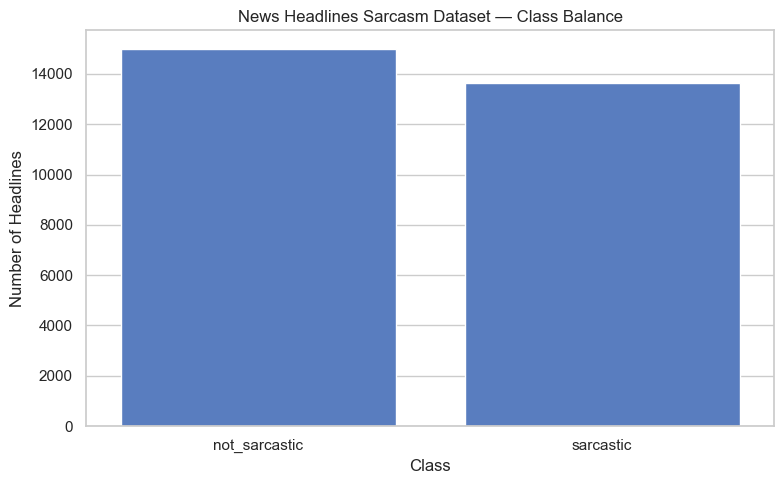

In [22]:
# ============================================================
# Class Distribution — Main Sarcasm Dataset
# ============================================================

plt.figure(figsize=(8, 5))

sarcasm_labels = headlines_raw["is_sarcastic"].map({
    0: "not_sarcastic",
    1: "sarcastic"
})

sns.countplot(
    x=sarcasm_labels,
    order=["not_sarcastic", "sarcastic"]
)

plt.title("News Headlines Sarcasm Dataset — Class Balance")
plt.xlabel("Class")
plt.ylabel("Number of Headlines")
plt.tight_layout()

plt.savefig(
    f"{CFG.OUTPUT_DIR}/sarcasm_class_distribution.png",
    dpi=140,
    bbox_inches="tight"
)

plt.show()

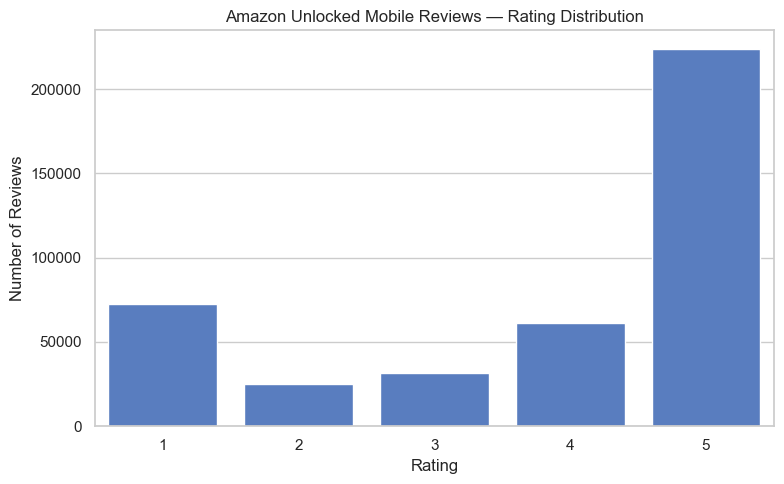

In [23]:
# ============================================================
# Amazon Dataset — Rating Distribution
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    x=amazon_raw["Rating"].dropna().astype(int)
)

plt.title("Amazon Unlocked Mobile Reviews — Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(
    f"{CFG.OUTPUT_DIR}/amazon_rating_distribution.png",
    dpi=140,
    bbox_inches="tight"
)

plt.show()

In [24]:
print("Main Sarcasm Dataset:")
display(headlines_raw.head())

print("\nAmazon Reviews Dataset:")
display(amazon_raw.head())

Main Sarcasm Dataset:


,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...



Amazon Reviews Dataset:


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


## 13. Data Cleaning

Cleaning is kept **conservative** on purpose. Sarcasm signals often live in exactly the things a
"thorough" cleaner would strip out — punctuation emphasis, capitalisation, repeated exclamation
marks, emoji, hashtags used as commentary (e.g. *"Great!!! Another update broke everything 🙄"*).
So this pipeline only:
- replaces URLs and @mentions with placeholder tokens,
- unwraps hashtags into plain words (`#neveragain` → `neveragain`) without deleting them,
- decodes HTML entities,
- normalises whitespace.

It does **not** lowercase, strip punctuation, remove stopwords, or remove emoji.


In [25]:
def clean_text(text):
    t = str(text)
    t = re.sub(r"http\S+|www\.\S+", "[URL]", t)
    t = re.sub(r"@\w+", "[USER]", t)
    t = re.sub(r"#(\w+)", r"\1", t)
    t = t.replace("&amp;", "&").replace("&lt;", "<").replace("&gt;", ">")
    t = re.sub(r"\s+", " ", t).strip()
    return t

headlines = headlines_raw.rename(columns={"is_sarcastic": "sarcasm", "headline": "text"})[["text", "sarcasm"]].copy()
headlines["text"] = headlines["text"].apply(clean_text)
headlines = headlines[headlines["text"].str.len() > 3].dropna().reset_index(drop=True)
print(f"Main sarcasm dataset after cleaning: {len(headlines)} rows")
print(headlines.sample(3, random_state=CFG.SEED))


Main sarcasm dataset after cleaning: 28619 rows
                                                    text  sarcasm
27927  states slow to shut down weak teacher educatio...        0
1660     drone places fresh kill on steps of white house        1
96     report: majority of instances of people gettin...        1


## 14. Leakage-Free Train / Validation / Test Split

**This is the main correctness fix in this notebook.** An earlier version built train/validation
data from the full sarcasm dataset, and then separately built a "held-out test" set again from
the *same* full dataset — with no check that the same headline didn't land in both. Reported
test numbers from that version (~97.7% accuracy / ~97.7% macro-F1) are therefore not trustworthy
as an independent-test result and are **not repeated in this notebook**.

The function below:
1. drops exact-duplicate texts *before* splitting,
2. does a single stratified 70/15/15 split (train/val/test),
3. asserts there is zero text overlap between the three resulting sets.

The assertion is not decorative — if it fails, the split code is wrong and the notebook stops
rather than silently reporting leaked numbers.


In [26]:
def clean_stratified_split(df, text_col, label_col,
                            train_size=0.70, val_size=0.15, test_size=0.15, seed=42):
    assert abs(train_size + val_size + test_size - 1.0) < 1e-6

    before = len(df)
    df = df.drop_duplicates(subset=[text_col]).reset_index(drop=True)
    if before - len(df):
        print(f"  Removed {before - len(df)} exact-duplicate texts before splitting.")

    train_df, temp_df = train_test_split(
        df, train_size=train_size, random_state=seed, stratify=df[label_col])
    rel_val = val_size / (val_size + test_size)
    val_df, test_df = train_test_split(
        temp_df, train_size=rel_val, random_state=seed, stratify=temp_df[label_col])

    tr, va, te = set(train_df[text_col]), set(val_df[text_col]), set(test_df[text_col])
    assert not (tr & va), "Leakage detected: train/val overlap!"
    assert not (tr & te), "Leakage detected: train/test overlap!"
    assert not (va & te), "Leakage detected: val/test overlap!"

    print(f"  train={len(train_df):>6}  val={len(val_df):>6}  test={len(test_df):>6}  "
          f"(no text overlap between splits — verified)")
    return train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)

print("Splitting the News Headlines Sarcasm Dataset (primary sarcasm task):")
sarc_train, sarc_val, sarc_test = clean_stratified_split(
    headlines, text_col="text", label_col="sarcasm", seed=CFG.SEED)

print(f"\nTrain sarcasm rate : {sarc_train['sarcasm'].mean():.3f}")
print(f"Val   sarcasm rate : {sarc_val['sarcasm'].mean():.3f}")
print(f"Test  sarcasm rate : {sarc_test['sarcasm'].mean():.3f}")


Splitting the News Headlines Sarcasm Dataset (primary sarcasm task):
  Removed 116 exact-duplicate texts before splitting.
  train= 19952  val=  4275  test=  4276  (no text overlap between splits — verified)

Train sarcasm rate : 0.475
Val   sarcasm rate : 0.476
Test  sarcasm rate : 0.475


### Sentiment task split

For the auxiliary sentiment task, the ABSA data already comes with an official train/trial
partition and a separate gold-labelled test partition (Phase B), so instead of re-splitting
randomly, the official partitioning is respected and only cross-checked for leakage:

- **Train/Val** ← `Laptop_Train_v2.csv` + `laptops-trial.csv` + `Restaurants_Train_v2.csv` + `restaurants-trial.csv` (split 85/15)
- **Test** ← `Laptops_Test_Data_PhaseB.csv` + `Restaurants_Test_Data_PhaseB.csv` (gold polarity labels, official test partition)

**Handling of the `conflict` polarity label:** SemEval's `conflict` label means a sentence
expresses *both* a positive and a negative opinion about the same aspect (e.g. *"fast but
noisy"*). There is no principled way to fold that into a positive/negative/neutral 3-class
scheme without inventing a rule, so `conflict` rows are **dropped** from the 3-class sentiment
task rather than silently merged into another class. This is stated explicitly here instead of
happening silently in the code, per the CA's own scientific-defensibility requirement.


## 15. Tokenization

RoBERTa uses **byte-level Byte-Pair Encoding (BPE)**: text is first mapped to bytes, then merged
greedily into subword units learned from RoBERTa's pretraining corpus. This means:

- rare or unseen words are still represented (as a sequence of familiar subwords) instead of
  becoming a single `[UNK]` token, unlike a fixed word-level vocabulary,
- the vocabulary stays a manageable size (~50k tokens) while still covering effectively any
  English text.

```
Raw text  ->  Byte-level BPE subword tokens  ->  input IDs  ->  attention mask  ->  RoBERTa
```

`input_ids` are the integer indices of each subword in RoBERTa's vocabulary; `attention_mask` is
a 0/1 mask telling the model which positions are real tokens versus padding.


In [27]:
tokenizer = RobertaTokenizerFast.from_pretrained(CFG.MODEL_NAME)

example = "Great, another update that broke everything."
enc = tokenizer(example, return_tensors="pt")
print("Text        :", example)
print("Tokens      :", tokenizer.convert_ids_to_tokens(enc["input_ids"][0]))
print("input_ids   :", enc["input_ids"][0].tolist())
print("attn_mask   :", enc["attention_mask"][0].tolist())
print(f"\nVocab size  : {tokenizer.vocab_size:,}")


Text        : Great, another update that broke everything.
Tokens      : ['<s>', 'Great', ',', 'Ġanother', 'Ġupdate', 'Ġthat', 'Ġbroke', 'Ġeverything', '.', '</s>']
input_ids   : [0, 19065, 6, 277, 2935, 14, 2263, 960, 4, 2]
attn_mask   : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Vocab size  : 50,265


## 16. PyTorch Dataset & DataLoaders

A single generic `TextDataset` class is reused for both tasks (sarcasm and sentiment) — it just
needs a list of texts and a list of integer labels. Two independent DataLoaders are built per
task (train/val/test for sarcasm; train/val/test for sentiment).

`WeightedRandomSampler`/oversampling from the earlier version is **not used** here: the main
sarcasm dataset is close to balanced (~47.5% / 52.5%), so oversampling would add complexity
without a clear benefit. Plain `shuffle=True` is used instead. If a real class imbalance shows up
in Section 20 (Focal Loss ablation), that is examined directly rather than assumed upfront.


In [29]:
# ============================================================
# PyTorch Dataset & DataLoaders
# Sarcasm Detection Only
# ============================================================

class TextDataset(Dataset):
    def __init__(self, texts, labels, tok, max_len):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tok = tok
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tok(
            self.texts[idx],
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "label": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }


# ============================================================
# Sarcasm Dataset
# ============================================================

ds_sarc_train = TextDataset(
    sarc_train["text"],
    sarc_train["sarcasm"],
    tokenizer,
    CFG.MAX_LEN
)

ds_sarc_val = TextDataset(
    sarc_val["text"],
    sarc_val["sarcasm"],
    tokenizer,
    CFG.MAX_LEN
)

ds_sarc_test = TextDataset(
    sarc_test["text"],
    sarc_test["sarcasm"],
    tokenizer,
    CFG.MAX_LEN
)


# ============================================================
# DataLoaders
# ============================================================

dl_sarc_train = DataLoader(
    ds_sarc_train,
    batch_size=CFG.BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

dl_sarc_val = DataLoader(
    ds_sarc_val,
    batch_size=CFG.BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

dl_sarc_test = DataLoader(
    ds_sarc_test,
    batch_size=CFG.BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


# ============================================================
# Summary
# ============================================================

print("=" * 60)
print("SARCASTIC TEXT DATA LOADERS")
print("=" * 60)

print(f"Training samples   : {len(ds_sarc_train):,}")
print(f"Validation samples : {len(ds_sarc_val):,}")
print(f"Test samples       : {len(ds_sarc_test):,}")

print("-" * 60)

print(f"Training batches   : {len(dl_sarc_train):,}")
print(f"Validation batches : {len(dl_sarc_val):,}")
print(f"Test batches       : {len(dl_sarc_test):,}")

print("=" * 60)

SARCASTIC TEXT DATA LOADERS
Training samples   : 19,952
Validation samples : 4,275
Test samples       : 4,276
------------------------------------------------------------
Training batches   : 1,247
Validation batches : 268
Test batches       : 268


## 17. Model 1 — TF-IDF + Logistic Regression Baseline

```
Text -> TF-IDF (unigrams+bigrams) -> Logistic Regression -> Sarcasm prediction
```

This is a bag-of-words baseline: it has no notion of word order or context beyond adjacent-word
bigrams. It is fast to train and a fair, standard point of comparison for the transformer models.


In [30]:
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2)),
    ("clf", LogisticRegression(max_iter=300, class_weight="balanced", random_state=CFG.SEED)),
])
baseline.fit(sarc_train["text"], sarc_train["sarcasm"])
print("Model 1 (TF-IDF + Logistic Regression) trained.")


Model 1 (TF-IDF + Logistic Regression) trained.


### Shared evaluation helper (used by every sarcasm model below)

In [31]:
def compute_binary_metrics(y_true, y_pred, y_prob_pos):
    acc = accuracy_score(y_true, y_pred)
    p_w, r_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    p_m, r_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    try:
        auc = roc_auc_score(y_true, y_prob_pos)
    except ValueError:
        auc = float("nan")
    return {
        "accuracy": acc, "precision_macro": p_m, "recall_macro": r_m, "macro_f1": f1_m,
        "weighted_f1": f1_w, "roc_auc": auc,
    }

base_pred = baseline.predict(sarc_test["text"])
base_prob = baseline.predict_proba(sarc_test["text"])[:, 1]
metrics_model1 = compute_binary_metrics(sarc_test["sarcasm"], base_pred, base_prob)
print("Model 1 (TF-IDF+LogReg) test metrics:")
for k, v in metrics_model1.items():
    print(f"  {k:<16}: {v:.4f}")
print()
print(classification_report(sarc_test["sarcasm"], base_pred,
                             target_names=["not_sarcastic", "sarcastic"], zero_division=0))


Model 1 (TF-IDF+LogReg) test metrics:
  accuracy        : 0.8396
  precision_macro : 0.8395
  recall_macro    : 0.8404
  macro_f1        : 0.8395
  weighted_f1     : 0.8397
  roc_auc         : 0.9169

               precision    recall  f1-score   support

not_sarcastic       0.86      0.82      0.84      2243
    sarcastic       0.82      0.86      0.84      2033

     accuracy                           0.84      4276
    macro avg       0.84      0.84      0.84      4276
 weighted avg       0.84      0.84      0.84      4276



## 18. Model 2 — Standard RoBERTa Sarcasm Classifier

```
Input text -> RoBERTa tokenizer -> RoBERTa-base encoder (12 layers, hidden=768, ~125M params)
           -> [CLS] contextual representation -> classification head -> {sarcastic, not_sarcastic}
```

The `[CLS]` token's final hidden state is used as a pooled sentence representation (RoBERTa
computes it via self-attention over the *entire* sequence, so it already encodes context from
every other token, unlike a bag-of-words vector). The head on top is a small MLP:

```
[CLS] (768) -> Dropout -> Linear(768→256) -> GELU -> Dropout -> Linear(256→2)
```

This model is single-task: it only has a sarcasm head, and is fine-tuned only on the sarcasm
training set.


In [32]:
class RobertaSarcasmClassifier(nn.Module):
    '''Standard single-task RoBERTa sarcasm classifier (Model 2).'''
    def __init__(self, model_name=CFG.MODEL_NAME, hidden_size=768, dropout=CFG.DROPOUT, n_classes=2):
        super().__init__()
        self.encoder = RobertaModel.from_pretrained(model_name)
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(hidden_size, 256), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(256, n_classes),
        )

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]
        return self.head(cls)

print("RobertaSarcasmClassifier defined.")


RobertaSarcasmClassifier defined.


## 19. Model 3 — Multi-Task RoBERTa (Sarcasm + Sentiment, shared encoder)

```
                     RoBERTa-base Encoder (shared)
                                |
                       [CLS] representation
                     +----------+----------+
                     |                     |
              Sarcasm Head           Sentiment Head
           (768→256→GELU→2)       (768→256→GELU→3)
                     |                     |
          {sarcastic, not_sarcastic}  {negative, neutral, positive}
```

Both heads read the *same* shared `[CLS]` representation from one RoBERTa encoder. The idea
being tested is whether forcing the encoder to also be useful for ordinary sentiment
classification produces a representation that is *also* better for sarcasm detection (since
sarcasm partly depends on sentiment-related signal) — this is exactly the empirical question the
Model 2 vs Model 3 comparison in Section 27 is designed to answer.

Total loss during training: **L = 0.70 · L_sarcasm + 0.30 · L_sentiment**, with the sarcasm task
weighted higher since it is the primary task and the sentiment task is auxiliary.


In [33]:
class MultiTaskRoberta(nn.Module):
    '''Shared RoBERTa encoder with two independent heads (Model 3).'''
    def __init__(self, model_name=CFG.MODEL_NAME, hidden_size=768, dropout=CFG.DROPOUT,
                 n_sarcasm=2, n_sentiment=3):
        super().__init__()
        self.encoder = RobertaModel.from_pretrained(model_name)
        self.sarcasm_head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(hidden_size, 256), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(256, n_sarcasm),
        )
        self.sentiment_head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(hidden_size, 256), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(256, n_sentiment),
        )

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]
        return self.sarcasm_head(cls), self.sentiment_head(cls), cls


class FocalLoss(nn.Module):
    '''Used only for the Section 21 ablation (Model 4), not for Models 2/3.'''
    def __init__(self, gamma=2.0, weight=None):
        super().__init__()
        self.gamma = gamma
        self.weight = weight

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.weight, reduction="none")
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()

print("MultiTaskRoberta and FocalLoss defined.")


MultiTaskRoberta and FocalLoss defined.


## 20. Training

Two training-loop functions are defined:

- `train_single_task()` — trains a sarcasm-only model (used for **Model 2**, CrossEntropyLoss,
  and **Model 4**, the Focal-Loss ablation).
- `train_multitask()` — trains the shared-encoder model (**Model 3**) by cycling through the
  sarcasm and sentiment DataLoaders together each step and combining their losses
  (`0.7·L_sarcasm + 0.3·L_sentiment`). Because the sentiment loader is shorter, it is restarted
  (cycled) whenever it runs out, so every sarcasm batch still gets paired with a sentiment batch.

Both loops track per-epoch train loss, validation loss, and validation macro-F1 (on the sarcasm
task) so that training curves can be plotted in Section 26, and both save the checkpoint with the
best validation macro-F1.


In [34]:
def make_optimizer_and_scheduler(model, train_loader_len, epochs=CFG.EPOCHS):
    opt = AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
    total_steps = train_loader_len * epochs
    warmup_steps = int(CFG.WARMUP_RATIO * total_steps)
    sched = get_linear_schedule_with_warmup(opt, num_warmup_steps=warmup_steps,
                                             num_training_steps=total_steps)
    return opt, sched


@torch.no_grad()
def evaluate_sarcasm_head(model, loader, device, is_multitask):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        ids  = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        y    = batch["label"]
        if is_multitask:
            logits, _, _ = model(ids, mask)
        else:
            logits = model(ids, mask)
        all_logits.append(logits.cpu())
        all_labels.append(y)
    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels).numpy()
    probs = F.softmax(logits, dim=1).numpy()
    preds = probs.argmax(1)
    loss = F.cross_entropy(logits, torch.tensor(labels)).item()
    metrics = compute_binary_metrics(labels, preds, probs[:, 1])
    metrics["loss"] = loss
    return metrics, preds, probs, labels


def train_single_task(model, train_loader, val_loader, device, epochs=CFG.EPOCHS,
                       loss_fn=None, ckpt_path="model.pt", tag="Model"):
    if loss_fn is None:
        loss_fn = nn.CrossEntropyLoss()
    opt, sched = make_optimizer_and_scheduler(model, len(train_loader), epochs)
    history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}
    best_f1 = -1.0
    model.to(device)

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for batch in tqdm(train_loader, desc=f"[{tag}] epoch {epoch}/{epochs}", leave=False):
            ids  = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            y    = batch["label"].to(device)

            logits = model(ids, mask)
            loss = loss_fn(logits, y)

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.MAX_GRAD_NORM)
            opt.step(); sched.step()
            running += loss.item()

        train_loss = running / len(train_loader)
        val_metrics, *_ = evaluate_sarcasm_head(model, val_loader, device, is_multitask=False)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])
        print(f"[{tag}] epoch {epoch}: train_loss={train_loss:.4f}  "
              f"val_loss={val_metrics['loss']:.4f}  val_macro_f1={val_metrics['macro_f1']:.4f}")

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            torch.save(model.state_dict(), ckpt_path)

    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return model, history


def train_multitask(model, sarc_train_loader, sent_train_loader, sarc_val_loader, device,
                     epochs=CFG.EPOCHS, alpha=CFG.ALPHA_SARCASM, beta=CFG.BETA_SENTIMENT,
                     ckpt_path="model.pt", tag="Model3"):
    opt, sched = make_optimizer_and_scheduler(model, len(sarc_train_loader), epochs)
    history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}
    best_f1 = -1.0
    model.to(device)

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        sent_iter = iter(sent_train_loader)
        for batch in tqdm(sarc_train_loader, desc=f"[{tag}] epoch {epoch}/{epochs}", leave=False):
            try:
                sbatch = next(sent_iter)
            except StopIteration:
                sent_iter = iter(sent_train_loader)
                sbatch = next(sent_iter)

            ids, mask, y = batch["input_ids"].to(device), batch["attention_mask"].to(device), batch["label"].to(device)
            sarc_logits, _, _ = model(ids, mask)
            loss_sarc = F.cross_entropy(sarc_logits, y)

            sids, smask, sy = sbatch["input_ids"].to(device), sbatch["attention_mask"].to(device), sbatch["label"].to(device)
            _, sent_logits, _ = model(sids, smask)
            loss_sent = F.cross_entropy(sent_logits, sy)

            loss = alpha * loss_sarc + beta * loss_sent

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.MAX_GRAD_NORM)
            opt.step(); sched.step()
            running += loss.item()

        train_loss = running / len(sarc_train_loader)
        val_metrics, *_ = evaluate_sarcasm_head(model, sarc_val_loader, device, is_multitask=True)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])
        print(f"[{tag}] epoch {epoch}: train_loss={train_loss:.4f}  "
              f"val_sarcasm_loss={val_metrics['loss']:.4f}  val_macro_f1={val_metrics['macro_f1']:.4f}")

        if val_metrics["macro_f1"] > best_f1:
            best_f1 = val_metrics["macro_f1"]
            torch.save(model.state_dict(), ckpt_path)

    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return model, history

print("Training functions defined.")


Training functions defined.


### Train Model 2 (standard RoBERTa, CrossEntropyLoss)

In [35]:
set_seed(CFG.SEED)
model2 = RobertaSarcasmClassifier()
model2, history2 = train_single_task(
    model2, dl_sarc_train, dl_sarc_val, CFG.DEVICE, epochs=CFG.EPOCHS,
    loss_fn=nn.CrossEntropyLoss(), ckpt_path=f"{CFG.OUTPUT_DIR}/model2_roberta.pt", tag="Model2-RoBERTa")


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[Model2-RoBERTa] epoch 1/4:   0%|          | 0/1247 [00:00<?, ?it/s]

KeyboardInterrupt: 

### Train Model 3 (multi-task RoBERTa, shared encoder)

In [36]:
set_seed(CFG.SEED)
model3 = MultiTaskRoberta()
model3, history3 = train_multitask(
    model3, dl_sarc_train, dl_sent_train, dl_sarc_val, CFG.DEVICE, epochs=CFG.EPOCHS,
    ckpt_path=f"{CFG.OUTPUT_DIR}/model3_multitask.pt", tag="Model3-MultiTask")


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


NameError: name 'dl_sent_train' is not defined

### Train Model 4 — RoBERTa + Focal Loss (ablation, optional)

This ablation directly tests whether Focal Loss (designed for *hard, heavily imbalanced*
classification problems) actually helps on this dataset, given that the main sarcasm dataset is
already close to balanced. Toggle `CFG.RUN_FOCAL_LOSS_ABLATION = False` to skip it.


In [ ]:
history4 = None
if CFG.RUN_FOCAL_LOSS_ABLATION:
    set_seed(CFG.SEED)
    model4 = RobertaSarcasmClassifier()
    class_counts = sarc_train["sarcasm"].value_counts().sort_index()
    class_weights = torch.tensor((1.0 / class_counts).values, dtype=torch.float).to(CFG.DEVICE)
    focal = FocalLoss(gamma=CFG.FOCAL_GAMMA, weight=class_weights)
    model4, history4 = train_single_task(
        model4, dl_sarc_train, dl_sarc_val, CFG.DEVICE, epochs=CFG.EPOCHS,
        loss_fn=focal, ckpt_path=f"{CFG.OUTPUT_DIR}/model4_focal.pt", tag="Model4-Focal")
else:
    model4 = None
    print("Focal Loss ablation skipped (CFG.RUN_FOCAL_LOSS_ABLATION = False).")


## 21. Validation Summary

Validation metrics were already computed after every epoch above (used for checkpoint
selection). This cell just prints the **best** validation macro-F1 achieved by each model, for a
quick side-by-side check before moving to the held-out test set.


In [ ]:
print(f"Model 2 (RoBERTa)      best val macro-F1: {max(history2['val_macro_f1']):.4f}")
print(f"Model 3 (Multi-Task)    best val macro-F1: {max(history3['val_macro_f1']):.4f}")
if history4 is not None:
    print(f"Model 4 (RoBERTa+Focal) best val macro-F1: {max(history4['val_macro_f1']):.4f}")


## 22. Final Test Evaluation

Every model below is evaluated **once**, on the same untouched `sarc_test` split created in
Section 14 — the first and only time the test set is used. Since the split was verified to have
zero text overlap with train/val, these numbers are a genuine held-out estimate, unlike the
leaked numbers from the earlier notebook version.


In [ ]:
metrics_model2, preds2, probs2, labels_test = evaluate_sarcasm_head(model2, dl_sarc_test, CFG.DEVICE, is_multitask=False)
metrics_model3, preds3, probs3, _            = evaluate_sarcasm_head(model3, dl_sarc_test, CFG.DEVICE, is_multitask=True)

print("Model 2 (Standard RoBERTa) — TEST metrics:")
for k, v in metrics_model2.items():
    if k != "loss":
        print(f"  {k:<16}: {v:.4f}")
print(classification_report(labels_test, preds2, target_names=["not_sarcastic", "sarcastic"], zero_division=0))

print("\nModel 3 (Multi-Task RoBERTa) — TEST metrics:")
for k, v in metrics_model3.items():
    if k != "loss":
        print(f"  {k:<16}: {v:.4f}")
print(classification_report(labels_test, preds3, target_names=["not_sarcastic", "sarcastic"], zero_division=0))

if model4 is not None:
    metrics_model4, preds4, probs4, _ = evaluate_sarcasm_head(model4, dl_sarc_test, CFG.DEVICE, is_multitask=False)
    print("\nModel 4 (RoBERTa + Focal Loss, ablation) — TEST metrics:")
    for k, v in metrics_model4.items():
        if k != "loss":
            print(f"  {k:<16}: {v:.4f}")
    print(classification_report(labels_test, preds4, target_names=["not_sarcastic", "sarcastic"], zero_division=0))
else:
    metrics_model4, preds4, probs4 = None, None, None

# Auxiliary sentiment head — evaluated on its OWN real held-out sentiment test set.
# (This is the fix for the earlier notebook's fake pseudo-sentiment labels: this
#  number reflects genuine sentiment classification performance, not a derived label.)
@torch.no_grad()
def evaluate_sentiment_head(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        ids, mask, y = batch["input_ids"].to(device), batch["attention_mask"].to(device), batch["label"]
        _, sent_logits, _ = model(ids, mask)
        all_logits.append(sent_logits.cpu()); all_labels.append(y)
    logits = torch.cat(all_logits); labels = torch.cat(all_labels).numpy()
    preds = F.softmax(logits, dim=1).numpy().argmax(1)
    acc = accuracy_score(labels, preds)
    _, _, f1_m, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    return acc, f1_m, preds, labels

if len(sent_test):
    sent_acc, sent_f1, sent_preds, sent_labels = evaluate_sentiment_head(model3, dl_sent_test, CFG.DEVICE)
    print(f"\nModel 3 auxiliary sentiment head — TEST accuracy={sent_acc:.4f}  macro-F1={sent_f1:.4f}")
    print(classification_report(sent_labels, sent_preds,
                                 target_names=["negative", "neutral", "positive"], zero_division=0))
else:
    print("\nNo sentiment test set available — skipping auxiliary head evaluation.")


## 23. Confusion Matrices

In [ ]:
models_to_plot = [("Model 2: RoBERTa", preds2), ("Model 3: Multi-Task RoBERTa", preds3)]
if preds4 is not None:
    models_to_plot.append(("Model 4: RoBERTa+Focal", preds4))

fig, axes = plt.subplots(1, len(models_to_plot), figsize=(6 * len(models_to_plot), 5))
if len(models_to_plot) == 1:
    axes = [axes]
for ax, (name, preds) in zip(axes, models_to_plot):
    cm = confusion_matrix(labels_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["not_sarcastic", "sarcastic"], yticklabels=["not_sarcastic", "sarcastic"])
    ax.set_title(name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/confusion_matrices.png", dpi=140, bbox_inches="tight")
plt.show()


## 24. ROC Curves

In [ ]:
plt.figure(figsize=(6, 6))
for name, prob in [("Model 1: TF-IDF+LogReg", base_prob),
                    ("Model 2: RoBERTa", probs2[:, 1]),
                    ("Model 3: Multi-Task RoBERTa", probs3[:, 1])] + (
                    [("Model 4: RoBERTa+Focal", probs4[:, 1])] if probs4 is not None else []):
    fpr, tpr, _ = roc_curve(labels_test if name != "Model 1: TF-IDF+LogReg" else sarc_test["sarcasm"], prob)
    auc = roc_auc_score(labels_test if name != "Model 1: TF-IDF+LogReg" else sarc_test["sarcasm"], prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Sarcasm Detection (held-out test set)")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/roc_curves.png", dpi=140, bbox_inches="tight")
plt.show()


## 25. Training Curves

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = range(1, CFG.EPOCHS + 1)

axes[0].plot(epochs_range, history2["train_loss"], marker="o", label="Model 2 train")
axes[0].plot(epochs_range, history2["val_loss"],   marker="o", linestyle="--", label="Model 2 val")
axes[0].plot(epochs_range, history3["train_loss"], marker="s", label="Model 3 train")
axes[0].plot(epochs_range, history3["val_loss"],   marker="s", linestyle="--", label="Model 3 val")
if history4 is not None:
    axes[0].plot(epochs_range, history4["train_loss"], marker="^", label="Model 4 train")
    axes[0].plot(epochs_range, history4["val_loss"],   marker="^", linestyle="--", label="Model 4 val")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Train / Val Loss")
axes[0].legend(fontsize=8)

axes[1].plot(epochs_range, history2["val_macro_f1"], marker="o", label="Model 2")
axes[1].plot(epochs_range, history3["val_macro_f1"], marker="s", label="Model 3")
if history4 is not None:
    axes[1].plot(epochs_range, history4["val_macro_f1"], marker="^", label="Model 4")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation Macro-F1"); axes[1].set_title("Validation Macro-F1")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/training_curves.png", dpi=140, bbox_inches="tight")
plt.show()


## 26. Model Comparison

All four models are evaluated on the **identical** clean test set (`sarc_test`), so this table is
a fair comparison. The final cell below auto-generates a short, data-driven discussion instead of
a pre-written one, since the actual numbers are only known once you run this notebook.


In [ ]:
rows = [
    {"Model": "1. TF-IDF + Logistic Regression", **metrics_model1},
    {"Model": "2. Standard RoBERTa", **{k: v for k, v in metrics_model2.items() if k != "loss"}},
    {"Model": "3. Multi-Task RoBERTa", **{k: v for k, v in metrics_model3.items() if k != "loss"}},
]
if metrics_model4 is not None:
    rows.append({"Model": "4. RoBERTa + Focal Loss (ablation)",
                 **{k: v for k, v in metrics_model4.items() if k != "loss"}})

comparison_df = pd.DataFrame(rows)[["Model", "accuracy", "precision_macro", "recall_macro", "macro_f1", "weighted_f1", "roc_auc"]]
comparison_df.columns = ["Model", "Accuracy", "Precision", "Recall", "Macro F1", "Weighted F1", "ROC-AUC"]
display(comparison_df.round(4))
comparison_df.round(4).to_csv(f"{CFG.OUTPUT_DIR}/model_comparison.csv", index=False)


### Auto-generated discussion (data-driven, not pre-written)

In [ ]:
best_row = comparison_df.loc[comparison_df["Macro F1"].idxmax()]
print(f"Best model by macro-F1 on the held-out test set: {best_row['Model']}  (macro-F1={best_row['Macro F1']:.4f})\n")

f1_tfidf = comparison_df.loc[comparison_df["Model"].str.startswith("1"), "Macro F1"].values[0]
f1_roberta = comparison_df.loc[comparison_df["Model"].str.startswith("2"), "Macro F1"].values[0]
f1_multitask = comparison_df.loc[comparison_df["Model"].str.startswith("3"), "Macro F1"].values[0]

print(f"RoBERTa vs TF-IDF        : {f1_roberta:.4f} vs {f1_tfidf:.4f}  -> "
      f"{'RoBERTa improves on the bag-of-words baseline' if f1_roberta > f1_tfidf else 'RoBERTa does NOT clearly beat the bag-of-words baseline on this test set'}.")
print(f"Multi-task vs single-task: {f1_multitask:.4f} vs {f1_roberta:.4f}  -> "
      f"{'auxiliary sentiment learning helped' if f1_multitask > f1_roberta else 'auxiliary sentiment learning did NOT help (or hurt) on this test set'}.")

if metrics_model4 is not None:
    f1_focal = comparison_df.loc[comparison_df["Model"].str.startswith("4"), "Macro F1"].values[0]
    print(f"Focal Loss vs CE (Model 4 vs Model 2): {f1_focal:.4f} vs {f1_roberta:.4f}  -> "
          f"{'Focal Loss helped despite near-balanced data' if f1_focal > f1_roberta else 'Focal Loss did not help — consistent with the dataset already being close to balanced'}.")

print("\nThese three lines should be copied into the written report's "
      "'Analysis of Performance and Suggestions for Improvement' section, "
      "along with the actual comparison_df table above.")


## 27. Sentiment-Incongruence Analysis

**What this section is, and is not.** Model 3's sentiment head (Section 22) is genuine,
supervised sentiment classification trained on real ABSA polarity labels — that is the auxiliary
*task*. This section is different: it is a **qualitative, post-hoc interpretability tool** that
compares a text's *surface* sentiment against an independently-modelled *emotional tone*, to show
*why* a sentence might read as sarcastic. It is not used to train or evaluate anything above, and
it does not produce sarcasm ground truth.

- **Surface sentiment** — `cardiffnlp/twitter-roberta-base-sentiment-latest` (positive/neutral/negative)
- **Underlying emotion** — `j-hartmann/emotion-english-distilroberta-base` (anger, disgust, fear, joy, sadness, surprise, neutral)

**Incongruence heuristic (display-only):** surface sentiment = positive **and** underlying
emotion ∈ {anger, disgust, fear, sadness} → flagged as *"positive wording, negative undertone"* —
shown next to the model's actual sarcasm prediction, as a possible explanation, not a substitute
for it.


In [ ]:
from transformers import pipeline as hf_pipeline

surf_pipe = hf_pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                         device=0 if CFG.DEVICE.type == "cuda" else -1, truncation=True, max_length=128)
emot_pipe = hf_pipeline("text-classification", model="j-hartmann/emotion-english-distilroberta-base",
                         device=0 if CFG.DEVICE.type == "cuda" else -1, truncation=True, max_length=128)

POS_LABELS = {"positive", "LABEL_2"}
NEG_EMOTIONS = {"anger", "disgust", "fear", "sadness"}

@torch.no_grad()
def predict_sarcasm(model3_, texts, threshold=0.5):
    model3_.eval()
    out = []
    for t in texts:
        enc = tokenizer(clean_text(t), max_length=CFG.MAX_LEN, padding="max_length",
                         truncation=True, return_tensors="pt")
        logits, _, _ = model3_(enc["input_ids"].to(CFG.DEVICE), enc["attention_mask"].to(CFG.DEVICE))
        prob = F.softmax(logits, dim=1)[0].cpu().numpy()
        out.append(("sarcastic" if prob[1] >= threshold else "not_sarcastic", float(prob[1])))
    return out

def incongruence_report(texts):
    surf = surf_pipe(list(texts))
    emot = emot_pipe(list(texts))
    sarcasm_preds = predict_sarcasm(model3, texts)
    rows = []
    for t, s, e, (sarc_label, sarc_prob) in zip(texts, surf, emot, sarcasm_preds):
        incongruent = (s["label"] in POS_LABELS) and (e["label"] in NEG_EMOTIONS)
        rows.append({
            "text": t[:70] + ("…" if len(t) > 70 else ""),
            "surface_sentiment": s["label"], "surface_score": round(s["score"], 2),
            "underlying_emotion": e["label"], "emotion_score": round(e["score"], 2),
            "incongruent (qualitative)": incongruent,
            "model_sarcasm_prediction": sarc_label, "sarcasm_prob": round(sarc_prob, 3),
        })
    return pd.DataFrame(rows)

demo_incongruence = [
    "I just love waiting three hours for my food.",
    "The new laptop works perfectly and has excellent battery life.",
    "Oh great, another meeting that could have been an email.",
    "The support team resolved my issue quickly and politely.",
]
display(incongruence_report(demo_incongruence))


### Qualitative cross-domain look (Amazon reviews) — explicitly not a sarcasm benchmark

The Amazon dataset has star ratings, not sarcasm labels. A 1-star review is often sincerely
negative, not sarcastic — so, unlike an earlier version of this notebook, **no "sarcasm accuracy"
is computed on Amazon data.** The cells below only show a small qualitative sample of what the
trained model predicts, alongside the incongruence signal, for discussion purposes.


In [ ]:
if amazon_raw is not None:
    text_col = find_col(amazon_raw, ["Reviews", "reviews", "review", "text"])
    rating_col = find_col(amazon_raw, ["Rating", "rating", "stars"])
    amz_sample = amazon_raw[[text_col, rating_col]].dropna().sample(
        min(6, len(amazon_raw)), random_state=CFG.SEED)
    amz_sample.columns = ["text", "star_rating"]
    amz_sample["text"] = amz_sample["text"].astype(str).apply(clean_text)

    qual_report = incongruence_report(amz_sample["text"].tolist())
    qual_report.insert(1, "star_rating", amz_sample["star_rating"].values)
    print("QUALITATIVE ONLY — no sarcasm ground truth exists for this domain. "
          "Do not report these as sarcasm accuracy/F1 numbers.")
    display(qual_report)
else:
    print("Amazon data not available — skipping.")


### Qualitative cross-domain look (Laptop / Restaurant ABSA sentences)

Same caveat as above: ABSA sentences have sentiment polarity ground truth, **not** sarcasm ground
truth, so this is shown as qualitative model behaviour only — never as a sarcasm-detection
benchmark score, unlike an earlier version of this notebook which incorrectly derived
"cross-domain sarcasm accuracy" from these polarity labels.


In [ ]:
qual_frames = []
for key, domain in [("laptop_testB", "laptop"), ("rest_testB", "restaurant")]:
    if key in absa_raw:
        f = build_sentiment_frame(absa_raw[key], domain)
        if f is not None and len(f):
            qual_frames.append(f.sample(min(3, len(f)), random_state=CFG.SEED))

if qual_frames:
    qual_absa = pd.concat(qual_frames, ignore_index=True)
    preds = predict_sarcasm(model3, qual_absa["text"].tolist())
    qual_absa["model_sarcasm_prediction"] = [p[0] for p in preds]
    qual_absa["sarcasm_prob"] = [round(p[1], 3) for p in preds]
    print("QUALITATIVE ONLY — 'polarity' here is a sentiment label, not a sarcasm label.")
    display(qual_absa[["domain", "text", "polarity", "model_sarcasm_prediction", "sarcasm_prob"]])


## 28. LIME Explainability

LIME (Local Interpretable Model-agnostic Explanations) perturbs the input text (removing words)
and observes how the predicted probability changes, to estimate which words pushed the
prediction toward "sarcastic" versus "not_sarcastic" for one specific input. It is a **local,
approximate, post-hoc** explanation — it does not describe the model's global reasoning, and
different runs can give slightly different word weights due to its random sampling.


In [ ]:
@torch.no_grad()
def predict_proba_lime(texts):
    model3.eval()
    out = []
    for t in texts:
        enc = tokenizer(clean_text(t), max_length=CFG.MAX_LEN, padding="max_length",
                         truncation=True, return_tensors="pt")
        logits, _, _ = model3(enc["input_ids"].to(CFG.DEVICE), enc["attention_mask"].to(CFG.DEVICE))
        out.append(F.softmax(logits, dim=1)[0].cpu().numpy())
    return np.array(out)

explainer = LimeTextExplainer(class_names=["not_sarcastic", "sarcastic"])

lime_examples = [
    sarc_test.loc[sarc_test["sarcasm"] == 1, "text"].iloc[0],
    sarc_test.loc[sarc_test["sarcasm"] == 0, "text"].iloc[0],
]

fig, axes = plt.subplots(1, len(lime_examples), figsize=(8 * len(lime_examples), 5))
if len(lime_examples) == 1:
    axes = [axes]
for ax, text in zip(axes, lime_examples):
    exp = explainer.explain_instance(text, predict_proba_lime, num_features=8, num_samples=300)
    prob = predict_proba_lime([text])[0]
    pred_id = int(np.argmax(prob))
    feats = sorted(exp.as_list(label=pred_id), key=lambda x: abs(x[1]), reverse=True)
    labs = [f[0] for f in feats]; ws = [f[1] for f in feats]
    ax.barh(range(len(labs)), ws, color=["#e74c3c" if w > 0 else "#3498db" for w in ws])
    ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Prediction: {CFG.SARCASM_ID2LABEL[pred_id]} (conf={prob[pred_id]:.2f})\n\"{text[:60]}\"", fontsize=9)
plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/lime_explanations.png", dpi=140, bbox_inches="tight")
plt.show()


## 29. Custom Text Prediction (Prototype Demo)

This is the CA's required "prototype": a simple function that takes free text and returns a
sarcasm prediction, confidence, sentiment, and an incongruence flag — matching the example I/O
format from the project brief. A Streamlit UI would be a thin wrapper around this same function
and is left as optional (not required for the CA).


In [ ]:
@torch.no_grad()
def predict(texts):
    model3.eval()
    rows = []
    for text in texts:
        enc = tokenizer(clean_text(text), max_length=CFG.MAX_LEN, padding="max_length",
                         truncation=True, return_tensors="pt")
        sarc_logits, sent_logits, _ = model3(enc["input_ids"].to(CFG.DEVICE), enc["attention_mask"].to(CFG.DEVICE))
        sarc_prob = F.softmax(sarc_logits, dim=1)[0].cpu().numpy()
        sent_prob = F.softmax(sent_logits, dim=1)[0].cpu().numpy()
        sarc_id = int(np.argmax(sarc_prob))
        sent_id = int(np.argmax(sent_prob))

        surf = surf_pipe([text])[0]
        emot = emot_pipe([text])[0]
        incongruent = (surf["label"] in POS_LABELS) and (emot["label"] in NEG_EMOTIONS)

        rows.append({
            "Text": text,
            "Sarcasm": CFG.SARCASM_ID2LABEL[sarc_id],
            "Confidence": f"{sarc_prob[sarc_id]*100:.1f}%",
            "Sentiment (auxiliary head)": CFG.SENTIMENT_ID2LABEL[sent_id],
            "Incongruence (qualitative)": "Detected" if incongruent else "Not detected",
        })
    return pd.DataFrame(rows)

demo_texts = [
    "I absolutely love waiting three hours for my food.",
    "The new laptop works perfectly and has excellent battery life.",
    "Oh sure, another software update that breaks everything.",
    "City council approves funding for a new public library.",
]
pd.set_option("display.max_colwidth", 60)
display(predict(demo_texts))


## 30. Error Analysis

Every prediction on the test set falls into one of four categories. Looking at concrete examples
from each — especially false positives and false negatives — is more informative for the CA
report than the aggregate metrics alone.


In [ ]:
err_df = sarc_test.copy().reset_index(drop=True)
err_df["pred"] = preds3
err_df["prob_sarcastic"] = probs3[:, 1]

def categorize(row):
    if row["sarcasm"] == 1 and row["pred"] == 1: return "TP"
    if row["sarcasm"] == 0 and row["pred"] == 1: return "FP"
    if row["sarcasm"] == 1 and row["pred"] == 0: return "FN"
    return "TN"

err_df["category"] = err_df.apply(categorize, axis=1)
print("Category counts (Model 3, test set):")
print(err_df["category"].value_counts())

for cat, label in [("FP", "False Positives (predicted sarcastic, actually not)"),
                    ("FN", "False Negatives (predicted not sarcastic, actually sarcastic)")]:
    print(f"\n--- {label} ---")
    sample = err_df[err_df["category"] == cat].sort_values("prob_sarcastic", ascending=(cat == "FN")).head(5)
    for _, r in sample.iterrows():
        print(f"  [{r['prob_sarcastic']:.2f}] {r['text']}")


**Why sarcasm is difficult** (for the "possible reasons" the CA rubric asks about) — expect
to see some of these in the false positives/negatives above:
- implicit sarcasm with no obvious lexical cue,
- missing conversational or real-world context the model never sees,
- reliance on world knowledge (e.g. knowing a claim is factually absurd),
- short text with too little context to disambiguate,
- headlines whose sarcasm depends on knowing the publication (The Onion vs. HuffPost) rather than
  the text alone — a form of dataset-specific shortcut the model may be partly relying on,
- domain shift for anything outside news headlines (see the qualitative sections above).


## 31. Strengths

- Uses a pre-trained language representation (RoBERTa) rather than learning language structure
  from scratch, which matters given the training set is only tens of thousands of examples.
- Self-attention captures contextual meaning across the whole sentence, unlike the bag-of-words
  TF-IDF baseline.
- Multi-task learning gives a second, real, supervised signal (sentiment) to the shared encoder;
  Section 26 empirically checks whether that signal actually improves sarcasm detection rather
  than assuming it does.
- Sentiment incongruence (Section 27) gives a human-interpretable *reason* to go with a
  prediction, without being used as (fake) ground truth anywhere in training or evaluation.
- LIME gives local, per-example explanations, useful for a viva walkthrough.
- Trained and evaluated on a real, human-annotated sarcasm dataset with a leakage-checked split —
  the reported numbers are a genuine estimate of generalisation, not an artefact of data leakage.

## 32. Limitations

- Sarcasm is highly context-dependent; this model only sees isolated text, no conversation
  history, speaker identity, or real-world/factual context.
- RoBERTa is far more computationally expensive than TF-IDF, and fine-tuning comfortably needs a
  GPU (Section 9 warns if none is detected).
- Performance is very likely domain-specific: a model trained on news headlines may not transfer
  well to social media, product reviews, or spoken dialogue (see the qualitative sections in 27).
- Sentiment incongruence is a **correlate**, not a definition, of sarcasm — it is deliberately
  never used as a label anywhere in this notebook, and should not be treated as one if this
  project is extended.
- LIME explanations are local approximations with sampling randomness; they are not a full
  account of the model's reasoning.
- The News Headlines dataset itself may carry a "publication-source" shortcut (sarcastic
  headlines mostly come from one satirical outlet), which the model could be partly exploiting
  instead of purely modelling sarcasm.
- English-only; no multilingual or code-mixed evaluation was attempted.

## 33. Possible Future Improvements

- Incorporate conversational context (e.g. Reddit/Twitter reply-chain sarcasm datasets) rather
  than isolated single sentences.
- Evaluate on a genuinely sarcasm-labelled dataset from a different domain, instead of the
  qualitative-only cross-domain checks used here, to get a real cross-domain sarcasm score.
- Try contrastive learning between sarcastic/non-sarcastic pairs with similar surface sentiment.
- Explore cross-attention between the sarcasm and sentiment heads (rather than two independent
  heads on a shared trunk) to let the tasks interact more directly.
- Add complementary explainability methods (SHAP, Integrated Gradients) alongside LIME.
- Predict sarcasm *intensity* rather than a binary label.
- Extend to multimodal sarcasm detection (text + image), and to multilingual data.

## 34. Final Conclusion

*(Fill in the blanks below with the actual numbers from Section 26 once you run this notebook —
they are intentionally not pre-filled.)*

This project fine-tuned RoBERTa for sarcasm detection in a standard single-task configuration and
in a multi-task configuration sharing its encoder with a genuinely-trained sentiment head, and
compared both against a TF-IDF + Logistic Regression baseline on a leakage-checked test split of
the News Headlines Sarcasm Dataset. The comparison table and auto-generated discussion in
Section 26 answer the project's central research question directly from the numbers actually
produced by this run, rather than from assumptions carried over from an earlier, methodologically
flawed version of this notebook. Sentiment incongruence was used strictly as a qualitative,
post-hoc interpretability signal (Section 27) and never as a substitute for supervised sarcasm
labels, in line with the scoping note in Section 3.


## 35. Summary of Changes from the Original Notebook

**What was changed, and why**

| # | Problem in the original notebook | Fix applied here |
|---|---|---|
| 1 | Test set built from the same pool as train/val, no overlap check → leaked ~97.7% test numbers | New `clean_stratified_split()` does one 70/15/15 stratified split with a hard `assert` that train/val/test share zero texts |
| 2 | Sentiment head trained on `sarcasm==1 → negative, sarcasm==0 → positive` (a copy of the sarcasm label, not real sentiment) | Sentiment head now trained only on real ABSA `polarity` labels, with `conflict` explicitly dropped (documented reason) rather than silently merged |
| 3 | ABSA cross-domain sarcasm computed as `negative polarity → sarcastic` | Removed. ABSA polarity is used only for the sentiment task; Laptop/Restaurant sarcasm predictions are shown as qualitative-only, clearly labelled "not a benchmark" |
| 4 | Amazon "sarcasm accuracy" computed from 1–2★ → sarcastic / 4–5★ → not sarcastic | Removed. Amazon data is used only for qualitative domain-transfer / incongruence examples |
| 5 | Main sarcasm dataset (news headlines) called "Twitter" throughout | Renamed to "News Headlines Sarcasm Dataset" everywhere |
| 6 | WeightedRandomSampler + mandatory Focal Loss assumed necessary | Dataset is close to balanced (~47.5/52.5), so plain shuffling is used by default; Focal Loss is kept only as an explicit, optional ablation (Model 4) that is evaluated, not assumed to help |
| 7 | Confidence gate of unclear training purpose | Removed; the final prediction is just the sarcasm head's own softmax probability |

**Final architecture:** shared `roberta-base` encoder (125M params, hidden=768) → two independent
heads (`Dropout → Linear(768→256) → GELU → Dropout → Linear(256→n_classes)`), one for sarcasm
(2-class) and one for sentiment (3-class); trained with `L = 0.7·L_sarcasm + 0.3·L_sentiment`.

**Dataset usage:**
- News Headlines Sarcasm Dataset → sole source of sarcasm train/val/test (leakage-checked).
- SemEval-2014 ABSA (Laptop+Restaurant) → sole source of sentiment train/val/test (official
  Train/Trial vs. Phase-B test partitioning; `conflict` dropped).
- Amazon reviews → qualitative domain-transfer/incongruence analysis only, no ground truth used.

**Final experiments:** Model 1 (TF-IDF+LogReg) vs. Model 2 (RoBERTa) vs. Model 3 (Multi-Task
RoBERTa) vs. Model 4 (RoBERTa+Focal, ablation) — all on the identical clean test split; plus a
separate, genuine evaluation of the sentiment head on its own test set.

**Final metrics:** see the `comparison_df` table and the auto-generated discussion in Section 26,
and the sentiment-head accuracy/macro-F1 printed in Section 22 — both are produced by actually
running this notebook, not pre-filled here.

**Remaining limitations:** see Section 32. The most important one to say out loud in a viva: this
notebook proves RoBERTa fine-tuning works as a *supervised classifier* on this specific dataset —
it does not, and does not claim to, prove that sentiment incongruence *causes* or *defines*
sarcasm; that remains an interpretability signal, not a validated theoretical claim.
